# This is your Python notebook
Start solving by adding a new cell below — write and run code, or jot notes in text cells as you go.

Problem statement:

Porter wants to build a regression model that predicts the estimated delivery time of a food order based on order details, restaurant information, order placement time, and delivery-partner availability.

The prediction helps:
- Customers receive more accurate delivery estimates.
- Delivery partners plan and manage their workload.
- Operations teams optimize delivery allocation and resource planning.
Other applications:

The same approach can be reused in:
- E-commerce platforms to predict package delivery time.
- Grocery delivery applications to estimate order arrival.
- Courier companies to predict shipment arrival times.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Task 1.2 – Import dataset

In [4]:
!gdown https://drive.google.com/uc?id=1kkgBGldeswHBgVKEJiqqG7VZvqZNMc-5 -O Porter.csv

Downloading...
From: https://drive.google.com/uc?id=1kkgBGldeswHBgVKEJiqqG7VZvqZNMc-5
To: /content/Porter.csv
100% 15.7M/15.7M [00:00<00:00, 94.8MB/s]


In [5]:
df = pd.read_csv("Porter.csv")

Task 1.3 – Inspect data structure

In [6]:
df.head()

,market_id,created_at,actual_delivery_time,store_primary_category,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_dashers,total_busy_dashers,total_outstanding_orders,estimated_store_to_consumer_driving_duration
0,1.0,2015-02-06 22:24:17,2015-02-06 23:11:17,4,1.0,4,3441,4,557,1239,33.0,14.0,21.0,861.0
1,2.0,2015-02-10 21:49:25,2015-02-10 22:33:25,46,2.0,1,1900,1,1400,1400,1.0,2.0,2.0,690.0
2,2.0,2015-02-16 00:11:35,2015-02-16 01:06:35,36,3.0,4,4771,3,820,1604,8.0,6.0,18.0,289.0
3,1.0,2015-02-12 03:36:46,2015-02-12 04:35:46,38,1.0,1,1525,1,1525,1525,5.0,6.0,8.0,795.0
4,1.0,2015-01-27 02:12:36,2015-01-27 02:58:36,38,1.0,2,3620,2,1425,2195,5.0,5.0,7.0,205.0


In [7]:
df.shape

(175777, 14)

In [8]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175777 entries, 0 to 175776
Data columns (total 14 columns):
 #   Column                                        Non-Null Count   Dtype  
---  ------                                        --------------   -----  
 0   market_id                                     175777 non-null  float64
 1   created_at                                    175777 non-null  object 
 2   actual_delivery_time                          175777 non-null  object 
 3   store_primary_category                        175777 non-null  int64  
 4   order_protocol                                175777 non-null  float64
 5   total_items                                   175777 non-null  int64  
 6   subtotal                                      175777 non-null  int64  
 7   num_distinct_items                            175777 non-null  int64  
 8   min_item_price                                175777 non-null  int64  
 9   max_item_price                                17

### Task 1.4 – Three Pandas Datetime Functions / Accessors

1. **pd.to_datetime()** – Converts string or other supported values into Pandas datetime objects.

2. **.dt.hour** – Extracts the hour component (0–23) from a datetime column.

3. **.dt.dayofweek** – Extracts the weekday, where Monday = 0 and Sunday = 6.

### Task 1.5 – Difference Between datetime, timedelta and Period

1. **datetime** – Represents a specific point in time, including date and time. Example: `2026-11-07 10:30:00`.

2. **timedelta** – Represents the duration or difference between two datetime values. Example: `45 minutes` (time taken for a Porter delivery).

3. **Period** – Represents a fixed calendar span such as a month, quarter or year. Example: `March 2024`.


Task 2.1: Convert `created_at` and `actual_delivery_time` from object type to proper datetime type.

In [9]:
df["created_at"] = pd.to_datetime(df['created_at'])
df["actual_delivery_time"] = pd.to_datetime(df['actual_delivery_time'])


Task 2.2: Create the target column by finding the time taken for each delivery, then convert it into a single numeric value in minutes.

In [10]:
df["actual_delivery_duration"] =  df["actual_delivery_time"] -df["created_at"]

In [11]:
df["actual_delivery_duration"] = df["actual_delivery_duration"]/60
df["actual_delivery_duration"] = df['actual_delivery_duration'].dt.total_seconds() / 60

In [12]:
df['order_hour'] = df['created_at'].dt.hour

df['order_day'] = df['created_at'].dt.dayofweek

In [13]:
df = df.drop(columns =['created_at','actual_delivery_time'])

In [14]:
df.isna().sum()

,0
market_id,0
store_primary_category,0
order_protocol,0
total_items,0
subtotal,0
num_distinct_items,0
min_item_price,0
max_item_price,0
total_onshift_dashers,0
total_busy_dashers,0


There are no null values present

In [15]:
df['store_primary_category'] = (
    df['store_primary_category'].astype(str)
)

In [16]:
df = pd.get_dummies(
    df,
    columns=['store_primary_category'],
    dtype=int
)

In [17]:
print("Dataset shape:", df.shape)

df.filter(
    like='store_primary_category_'
).head()

Dataset shape: (175777, 87)


,store_primary_category_0,store_primary_category_1,store_primary_category_10,store_primary_category_11,store_primary_category_12,store_primary_category_13,store_primary_category_14,store_primary_category_15,store_primary_category_16,store_primary_category_17,...,store_primary_category_66,store_primary_category_67,store_primary_category_68,store_primary_category_69,store_primary_category_7,store_primary_category_70,store_primary_category_71,store_primary_category_72,store_primary_category_8,store_primary_category_9
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [18]:
print(df.filter(
    like='store_primary_category_'
).shape)

print(df.columns.tolist())

(175777, 73)
['market_id', 'order_protocol', 'total_items', 'subtotal', 'num_distinct_items', 'min_item_price', 'max_item_price', 'total_onshift_dashers', 'total_busy_dashers', 'total_outstanding_orders', 'estimated_store_to_consumer_driving_duration', 'actual_delivery_duration', 'order_hour', 'order_day', 'store_primary_category_0', 'store_primary_category_1', 'store_primary_category_10', 'store_primary_category_11', 'store_primary_category_12', 'store_primary_category_13', 'store_primary_category_14', 'store_primary_category_15', 'store_primary_category_16', 'store_primary_category_17', 'store_primary_category_18', 'store_primary_category_19', 'store_primary_category_2', 'store_primary_category_20', 'store_primary_category_21', 'store_primary_category_22', 'store_primary_category_23', 'store_primary_category_24', 'store_primary_category_25', 'store_primary_category_26', 'store_primary_category_27', 'store_primary_category_28', 'store_primary_category_29', 'store_primary_category_3', 

Task 3.1: Visualize relationships between the target and key features — for example a correlation heatmap and scatterplots of `time_taken_mins` against `subtotal`, and `total_items` against `subtotal`.

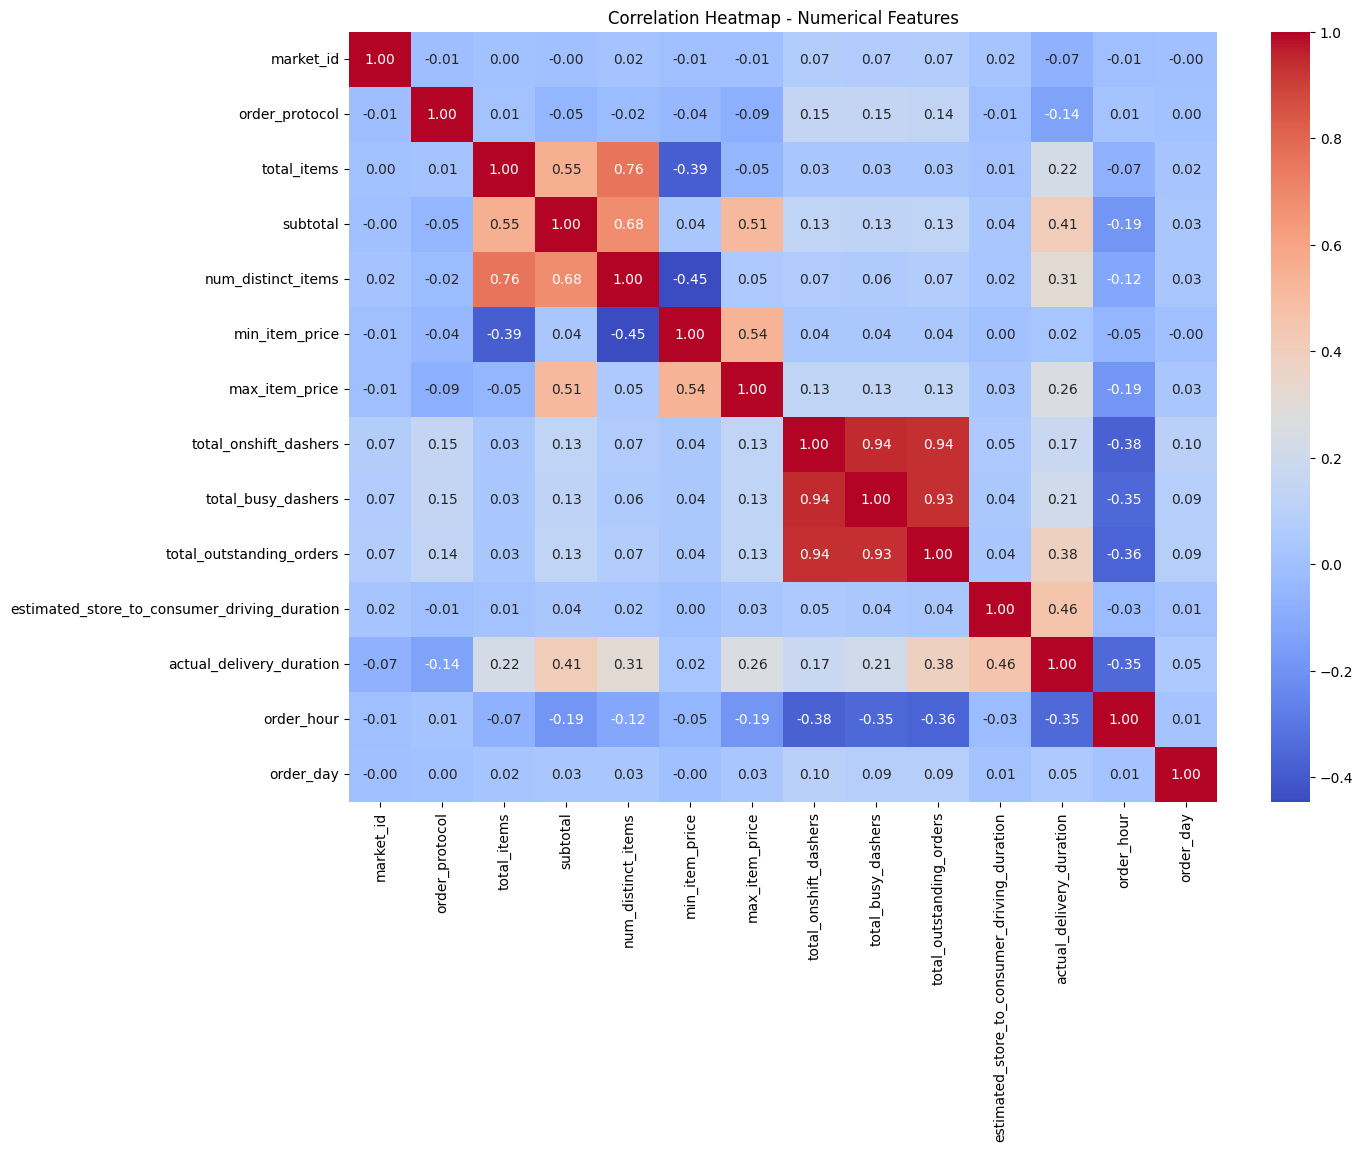

In [19]:
# Exclude One-Hot encoded columns
numeric_cols = df.select_dtypes(include='number').columns

numeric_cols = [
    col for col in numeric_cols
    if not col.startswith('store_primary_category_')
]

plt.figure(figsize=(14, 10))

sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap - Numerical Features')
plt.show()

### Task 3.1 – Correlation Heatmap: Key Observations

**1. Features positively correlated with delivery duration:**

- `estimated_store_to_consumer_driving_duration` has the highest positive correlation (0.46), indicating that longer estimated driving durations are associated with longer delivery times.
- `subtotal` has a positive correlation of 0.41, suggesting that higher-value orders tend to be associated with longer delivery durations.
- `total_outstanding_orders` has a correlation of 0.38, indicating that higher pending order volumes may be associated with increased delivery times.
- `num_distinct_items` has a correlation of 0.31, showing a moderate positive relationship with delivery duration.

**2. Features negatively correlated with delivery duration:**

- `order_hour` has a negative correlation of -0.35, suggesting that delivery duration varies depending on the hour at which an order is placed.
- `order_protocol` has a weak negative correlation of -0.14.

**3. Multicollinearity observations:**

- `total_onshift_dashers` and `total_busy_dashers` have a high correlation of 0.94.
- `total_onshift_dashers` and `total_outstanding_orders` have a correlation of 0.94.
- `total_busy_dashers` and `total_outstanding_orders` have a correlation of 0.93.
- `total_items` and `num_distinct_items` have a correlation of 0.76.

These relationships indicate potential multicollinearity among some input features.

**4. Key conclusion:**

Estimated driving duration, subtotal and outstanding orders show relatively stronger linear relationships with delivery duration. However, correlation does not imply causation. Features with low linear correlation should not be discarded without further investigation, as they may still contribute to model predictions through nonlinear relationships.

1. Scatterplot – Delivery time vs Subtotal

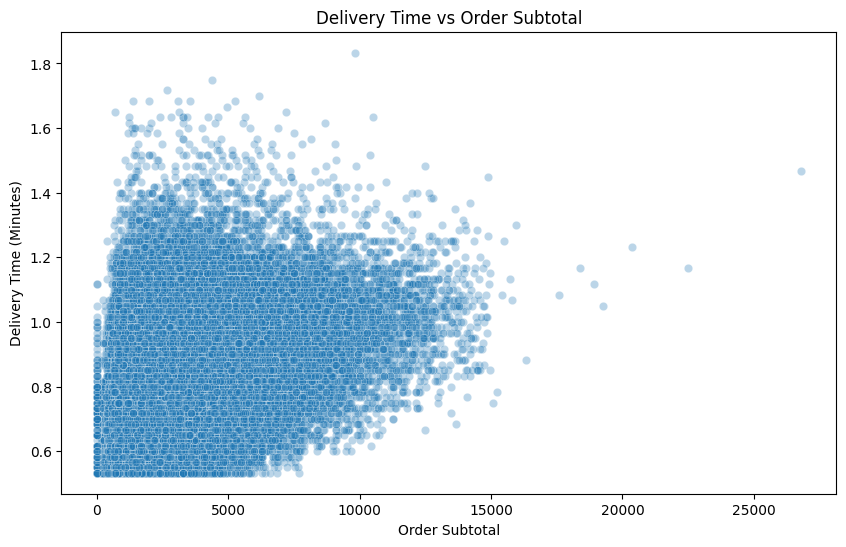

In [20]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='subtotal',
    y='actual_delivery_duration',
    alpha=0.3
)

plt.title('Delivery Time vs Order Subtotal')
plt.xlabel('Order Subtotal')
plt.ylabel('Delivery Time (Minutes)')
plt.show()

The scatterplot shows considerable variation in delivery time across different order subtotals, with no clear linear relationship. This indicates that order value alone may not be a reliable predictor of delivery duration.

Scatterplot — Total Items vs Order Subtotal

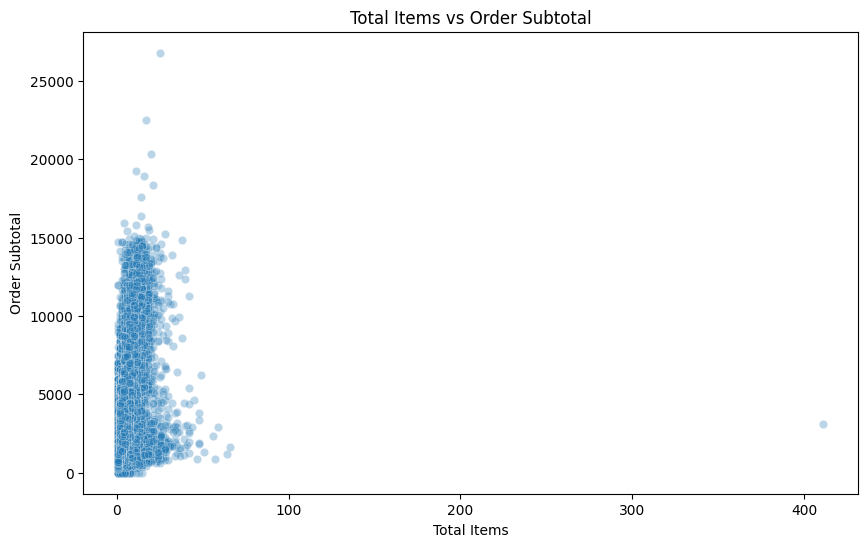

In [21]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='total_items',
    y='subtotal',
    alpha=0.3
)

plt.title('Total Items vs Order Subtotal')
plt.xlabel('Total Items')
plt.ylabel('Order Subtotal')
plt.show()

The scatterplot indicates a general positive relationship between the number of items and order subtotal. However, considerable variation in subtotal exists for similar item counts, possibly due to differences in item prices. An extreme observation with approximately 410 items is also visible and requires further investigation during outlier treatment.

**Task 3.2: Why is it important to check for outliers before training a model?**

Outliers are extreme values that differ significantly from the majority of observations. In the Porter dataset, unusual values such as orders with approximately 410 items may influence the model during training. They can distort statistical measures, affect feature relationships, and increase prediction errors, particularly in models sensitive to extreme values. Identifying and investigating outliers before training helps improve model reliability and prediction accuracy. However, genuine observations should not be removed without proper justification.

**Task 3.3: Name three methods that can be used to detect or remove outliers.**

1. **IQR (Interquartile Range) Method:** Identifies outliers using the lower and upper bounds calculated from the first and third quartiles.

2. **Z-Score Method:** Identifies values that are significantly far from the mean, typically beyond ±3 standard deviations.

3. **Capping (Winsorization):** Handles outliers by replacing extreme values with specified upper and lower percentile limits instead of removing the observations.

**Task 3.4: Apply an outlier detection method to the data, print how many rows were flagged, and remove those rows.**

**Step 1: Select numerical columns**
We should exclude categorical columns such as market_id, order_protocol, order_hour, order_day, and the one-hot encoded category columns.

In [22]:
numeric_cols = [
    'total_items',
    'subtotal',
    'num_distinct_items',
    'min_item_price',
    'max_item_price',
    'total_onshift_dashers',
    'total_busy_dashers',
    'total_outstanding_orders',
    'estimated_store_to_consumer_driving_duration',
    'actual_delivery_duration'
]

In [23]:
Q1 = df[numeric_cols].quantile(0.25)
Q3 = df[numeric_cols].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (df[numeric_cols] < lower_bound) |
    (df[numeric_cols] > upper_bound)
).any(axis=1)

# Count rows flagged as outliers
outlier_count = outlier_mask.sum()

print("Number of rows flagged as outliers:", outlier_count)

# Remove outlier rows
df = df.loc[~outlier_mask].copy()

print("Shape after removing outliers:", df.shape)

Number of rows flagged as outliers: 26520
Shape after removing outliers: (149257, 87)


Using the IQR method, 26,520 rows (approximately 15.09% of the original dataset) were identified as outliers and removed. The resulting dataset contains 149,257 rows and 87 columns. This helps reduce the influence of extreme values on subsequent model training.

**Task 3.5: Re-plot the same scatterplot from Task 3.1 after removing outliers, and compare it to the original to confirm the cleaning helped.**

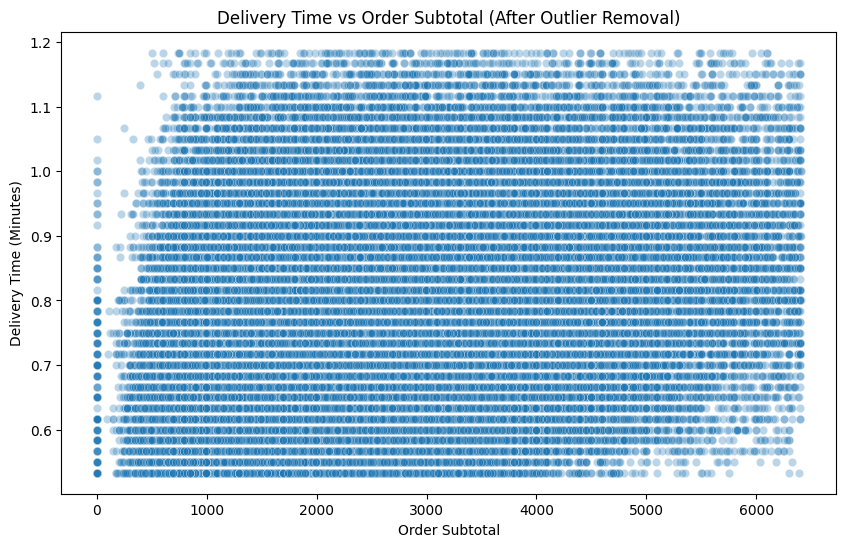

In [24]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='subtotal',
    y='actual_delivery_duration',
    alpha=0.3
)

plt.title('Delivery Time vs Order Subtotal (After Outlier Removal)')
plt.xlabel('Order Subtotal')
plt.ylabel('Delivery Time (Minutes)')
plt.show()

After outlier removal, the scatterplot shows a reduced range of values for both order subtotal and delivery duration. The distribution is more compact, making the main data pattern easier to observe. However, no strong linear relationship between order subtotal and delivery time is evident.

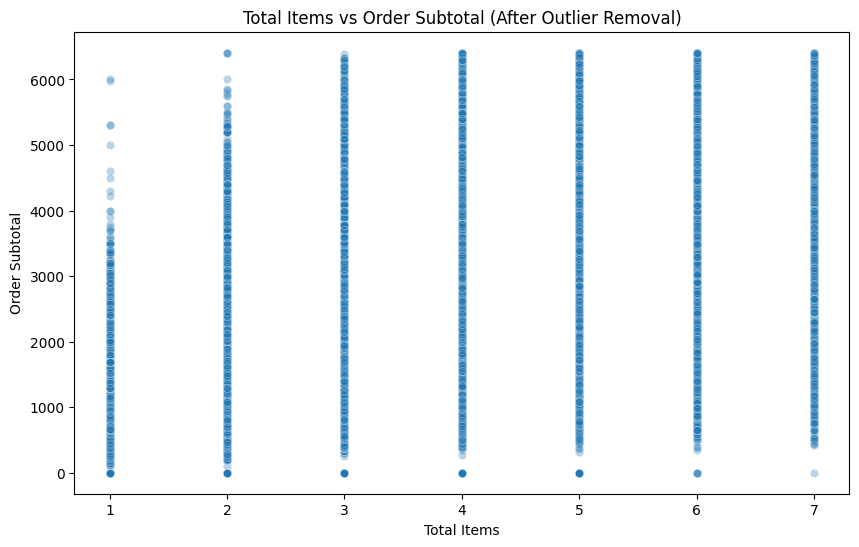

In [25]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='total_items',
    y='subtotal',
    alpha=0.3
)

plt.title('Total Items vs Order Subtotal (After Outlier Removal)')
plt.xlabel('Total Items')
plt.ylabel('Order Subtotal')
plt.show()

After outlier removal, the number of items and order subtotal are within a narrower range. The scatterplot shows a general positive relationship between the two variables, although considerable variation in subtotal remains for each item count. Removing outliers has improved the visualization by reducing the influence of extreme values.

**Task 3.5 – Overall conclusion**
Both scatterplots now show a more compact distribution after outlier removal. The extreme observations have been reduced, making the main data patterns easier to interpret. However, outlier removal has not fundamentally changed the relationships between the variables.

**Task 3.6: Visualize order volume by day of week and hour of day, and check whether time of day affects delivery time.**

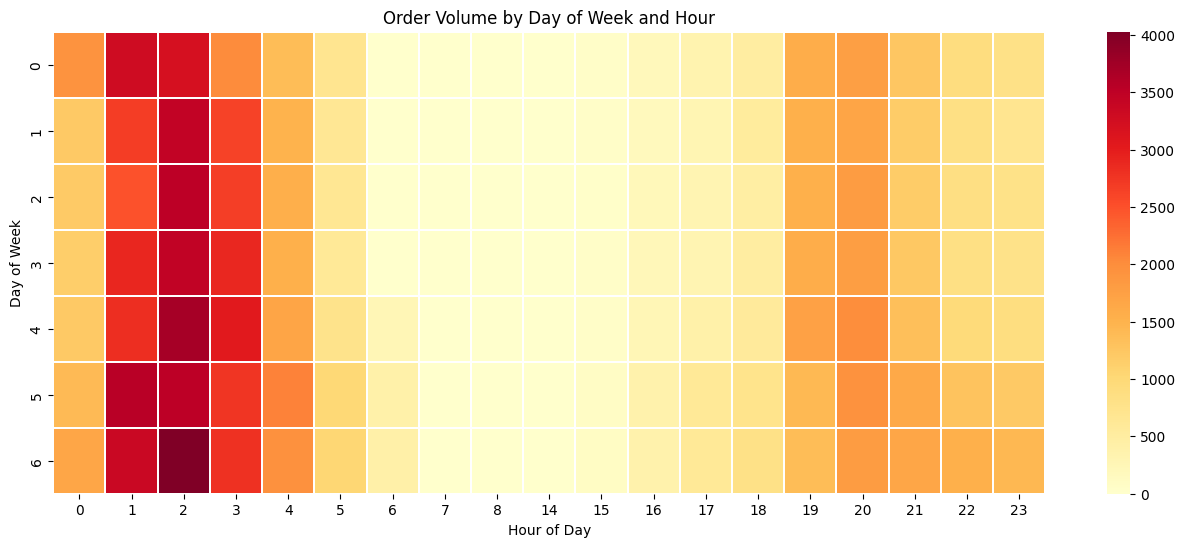

In [26]:
# Calculate order count for each day and hour
order_volume = df.pivot_table(
    index='order_day',
    columns='order_hour',
    values='total_items',
    aggfunc='count',
    fill_value=0
)

# Plot heatmap
plt.figure(figsize=(16, 6))

sns.heatmap(
    order_volume,
    cmap='YlOrRd',
    linewidths=0.3
)

plt.title('Order Volume by Day of Week and Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Day of Week')
plt.show()

The heatmap indicates that order volume is generally highest between 1 AM and 3 AM, with peak activity around 2 AM. A secondary increase in orders is observed during the evening hours (7 PM–8 PM), while order volume is relatively low during the morning hours.

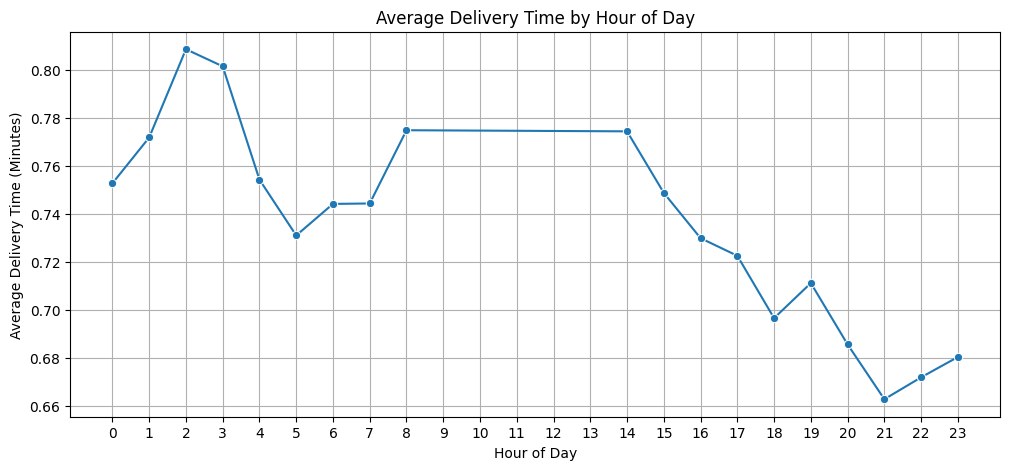

In [27]:
hourly_delivery = df.groupby('order_hour')['actual_delivery_duration'].mean()

plt.figure(figsize=(12, 5))

sns.lineplot(x=hourly_delivery.index, y=hourly_delivery.values, marker='o')

plt.title('Average Delivery Time by Hour of Day')
plt.xlabel('Hour of Day')
plt.ylabel('Average Delivery Time (Minutes)')
plt.xticks(range(24))
plt.grid(True)
plt.show()

The average delivery duration varies across different hours of the day. It is highest during the early morning hours, particularly around 2 AM–3 AM, and generally decreases during the evening, reaching its lowest level around 9 PM. This suggests that the time of order placement may influence delivery duration.

**Task 4.1: Split data into training and test sets**

In [28]:
X = df.drop('actual_delivery_duration', axis=1)

y = df['actual_delivery_duration']

In [29]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [30]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (119405, 86)
X_test shape: (29852, 86)
y_train shape: (119405,)
y_test shape: (29852,)


The cleaned and encoded dataset was split into training and testing sets using an 80:20 ratio with random_state=42 to ensure reproducibility. The training set contains 119,405 records, while the testing set contains 29,852 records, with 86 independent features in both sets.

**Task 4.2: Train a random forest regression model as your baseline.**

In [32]:
from sklearn.ensemble import RandomForestRegressor

In [33]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

RandomForestRegressor(n_jobs=-1, random_state=42)

A baseline Random Forest Regression model was successfully trained using 100 decision trees on the training dataset. The model will be used to predict delivery duration and evaluate its performance on unseen test data.

**Task 4.3: Evaluate the random forest on the test set using multiple error metrics, and identify which features matter most.**

In [34]:
# Generate predictions
y_pred = rf_model.predict(X_test)

# Display first 10 predictions
print("Actual values:", y_test.head(10).values)
print("Predicted values:", y_pred[:10])

Actual values: [0.6        0.81666667 0.73333333 0.76666667 1.         0.66666667
 0.9        0.6        0.81666667 0.76666667]
Predicted values: [0.60983333 0.861      0.7065     0.78016667 0.938      0.671
 0.89366667 0.58716667 0.791      0.7775    ]


In [41]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 0.02039449059806156
MSE: 0.0007632213531198363
RMSE: 0.027626461103801122
R2 Score: 0.9593482726038424


The baseline Random Forest model achieved an R² score of 0.9593, explaining approximately 95.93% of the variation in the target variable. The model recorded an MAE of 0.0204 and an RMSE of 0.0276, indicating low prediction errors and strong performance on the test dataset.

In [42]:
# Extract feature importance
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display top 15 features
print(feature_importance.head(15))

                                         Feature  Importance
10  estimated_store_to_consumer_driving_duration    0.255625
9                       total_outstanding_orders    0.247381
7                          total_onshift_dashers    0.177590
11                                    order_hour    0.080664
3                                       subtotal    0.080000
0                                      market_id    0.071973
12                                     order_day    0.027637
1                                 order_protocol    0.020602
8                             total_busy_dashers    0.017687
6                                 max_item_price    0.005563
5                                 min_item_price    0.004605
4                             num_distinct_items    0.002852
2                                    total_items    0.001931
47                      store_primary_category_4    0.000527
54                     store_primary_category_46    0.000449


Feature importance analysis shows that estimated store-to-consumer driving duration (25.56%), total outstanding orders (24.74%), and total on-shift dashers (17.76%) are the three most influential features in predicting delivery duration. Together, they contribute approximately 68.05% of the total feature importance. This indicates that travel duration and operational workload play significant roles in the model's predictions, while item-related features have relatively lower importance.

Other classical machine learning algorithms suitable for this regression problem include:
1. Linear Regression – Predicts a continuous target using a linear relationship between input features and the target.
2. K-Nearest Neighbors (KNN) Regression – Predicts delivery duration based on the average target values of nearby data points.
3. Decision Tree Regression – Uses decision rules to predict continuous values.
4. Gradient Boosting Regression – Builds multiple trees sequentially, with each tree attempting to correct previous errors.
5. Support Vector Regression (SVR) – Uses support vector techniques to predict continuous values.

**Task 5.1: Scale the feature data before feeding it into a neural network, and explain why scaling matters here but wasn't required for the random forest.**

Feature scaling is important for Neural Networks because the input features have different ranges and magnitudes. For example, `subtotal` may have values in the thousands, while `order_hour` ranges from 0 to 23 and one-hot encoded features contain only 0s and 1s. Since Neural Networks use gradient descent for learning, differences in feature scales can affect weight updates and make training slower or less stable. Scaling brings the features to a comparable range, helping the model learn more efficiently.

Random Forest, on the other hand, is a tree-based algorithm that makes decisions using feature thresholds. Since it relies on splitting data based on feature values rather than gradient-based weight updates, it is generally not sensitive to differences in feature scales and does not require feature scaling.

In [43]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Fit on training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Training data shape: (119405, 86)
Testing data shape: (29852, 86)


The training and testing feature datasets were successfully standardized using StandardScaler. The training dataset contains 119,405 records with 86 features, while the testing dataset contains 29,852 records with the same 86 features. The same scaling parameters fitted on the training data were applied to the testing data to prevent data leakage.

**Task 5.2 – PyTorch implementation**

In [44]:
import torch
import torch.nn as nn

class DeliveryDurationNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(86, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)


# Create the model
model = DeliveryDurationNN()

print(model)

DeliveryDurationNN(
  (network): Sequential(
    (0): Linear(in_features=86, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


**Task 5.3: Compile the model with an optimizer and loss function suited to this regression task, and briefly justify your choice of optimizer.**

In [45]:
import torch.optim as optim

# Define loss function
criterion = nn.MSELoss()

# Define optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: MSELoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


The model was successfully configured with Mean Squared Error (MSE) as the loss function and Adam as the optimizer, using a learning rate of 0.001. MSE is appropriate for measuring prediction errors in this regression problem. Adam was selected because it adaptively adjusts learning rates for individual parameters, helping the neural network achieve efficient and stable convergence during training.

**Task 5.4: Train the network for a reasonable number of epochs, then plot training vs validation loss to check for overfitting**

Step 1: Prepare training and validation data
We already have a separate test dataset. We should not use it during training or validation.

Let's split the existing training data into:
- 80% training data
- 20% validation data

In [46]:
from sklearn.model_selection import train_test_split

X_train_nn, X_val_nn, y_train_nn, y_val_nn = train_test_split(
    X_train_scaled,
    y_train,
    test_size=0.2,
    random_state=42
)

**Step 2: Convert data into PyTorch tensors**
**PyTorch models work with tensors, so we need to convert our NumPy arrays and Pandas Series.**

In [47]:
import torch

X_train_tensor = torch.tensor(X_train_nn, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_nn, dtype=torch.float32)

y_train_tensor = torch.tensor(
    y_train_nn.values.reshape(-1, 1),
    dtype=torch.float32
)

y_val_tensor = torch.tensor(
    y_val_nn.values.reshape(-1, 1),
    dtype=torch.float32
)

**Step 3: Create DataLoaders**
**Batches of 256 records rather than feeding the entire dataset at once.**

In [48]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)

train_loader = DataLoader(
    train_dataset, batch_size=256, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=256, shuffle=False
)

**Step 4: Train the neural network**
**We will track the training and validation losses for every epoch.**

In [49]:
epochs = 50

train_losses = []
val_losses = []

for epoch in range(epochs):

    # Training phase
    model.train()
    running_train_loss = 0.0

    for X_batch, y_batch in train_loader:

        optimizer.zero_grad()

        predictions = model(X_batch)

        loss = criterion(predictions, y_batch)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * X_batch.size(0)

    epoch_train_loss = running_train_loss / len(train_dataset)
    train_losses.append(epoch_train_loss)

    # Validation phase
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:

            predictions = model(X_batch)

            loss = criterion(predictions, y_batch)

            running_val_loss += loss.item() * X_batch.size(0)

    epoch_val_loss = running_val_loss / len(val_dataset)
    val_losses.append(epoch_val_loss)

    print(
        f"Epoch [{epoch+1}/{epochs}], "
        f"Training Loss: {epoch_train_loss:.6f}, "
        f"Validation Loss: {epoch_val_loss:.6f}"
    )

Epoch [1/50], Training Loss: 0.032337, Validation Loss: 0.002380
Epoch [2/50], Training Loss: 0.001929, Validation Loss: 0.001596
Epoch [3/50], Training Loss: 0.001429, Validation Loss: 0.001325
Epoch [4/50], Training Loss: 0.001171, Validation Loss: 0.001106
Epoch [5/50], Training Loss: 0.001003, Validation Loss: 0.000926
Epoch [6/50], Training Loss: 0.000846, Validation Loss: 0.000854
Epoch [7/50], Training Loss: 0.000780, Validation Loss: 0.000720
Epoch [8/50], Training Loss: 0.000691, Validation Loss: 0.000692
Epoch [9/50], Training Loss: 0.000594, Validation Loss: 0.000663
Epoch [10/50], Training Loss: 0.000541, Validation Loss: 0.000590
Epoch [11/50], Training Loss: 0.000480, Validation Loss: 0.000461
Epoch [12/50], Training Loss: 0.000448, Validation Loss: 0.000536
Epoch [13/50], Training Loss: 0.000442, Validation Loss: 0.000361
Epoch [14/50], Training Loss: 0.000345, Validation Loss: 0.000370
Epoch [15/50], Training Loss: 0.000318, Validation Loss: 0.000401
Epoch [16/50], Trai

**Step 5: Plot training vs validation loss**

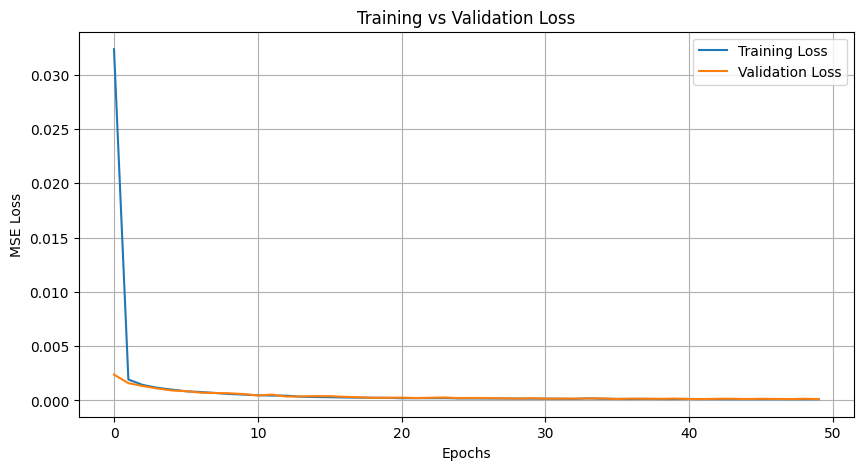

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')

plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.title('Training vs Validation Loss')

plt.legend()
plt.grid(True)
plt.show()

The neural network was trained for 50 epochs, and the training and validation losses were monitored to evaluate its performance. Both losses decreased rapidly during the initial epochs and gradually stabilized at very low values. The training and validation loss curves remain close to each other, with no significant increase in validation loss. This indicates that the model is learning effectively and there is no clear evidence of overfitting. The similar loss trends also suggest good generalization to unseen validation data.

**Task 5.5: Evaluate the trained network on the test set using the same set of metrics used for the random forest, and directly compare the two models' results.**

**Step 1: Prepare the test data as PyTorch tensors**
We already scaled X_test using the StandardScaler fitted on the training data

In [51]:
import torch

X_test_tensor = torch.tensor(
    X_test_scaled, dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test.values.reshape(-1, 1),
    dtype=torch.float32
)

**Step 2: Generate predictions**
Put the model in evaluation mode and disable gradient calculations.

In [52]:
model.eval()

with torch.no_grad():
    y_pred_nn = model(X_test_tensor)

# Convert predictions into NumPy array
y_pred_nn = y_pred_nn.numpy().flatten()

**Step 3: Calculate evaluation metrics**

In [53]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

mae_nn = mean_absolute_error(y_test, y_pred_nn)

mse_nn = mean_squared_error(y_test, y_pred_nn)

rmse_nn = np.sqrt(mse_nn)

r2_nn = r2_score(y_test, y_pred_nn)

print("Neural Network Performance")
print("MAE:", mae_nn)
print("MSE:", mse_nn)
print("RMSE:", rmse_nn)
print("R2 Score:", r2_nn)

Neural Network Performance
MAE: 0.006881460039161134
MSE: 0.00010803052257136588
RMSE: 0.01039377325957065
R2 Score: 0.9942459322762868


In [54]:
comparison = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2 Score'],
    'Random Forest': [mae, mse, rmse, r2],
    'Neural Network': [mae_nn, mse_nn, rmse_nn, r2_nn]
})

print(comparison)

     Metric  Random Forest  Neural Network
0       MAE       0.020394        0.006881
1       MSE       0.000763        0.000108
2      RMSE       0.027626        0.010394
3  R2 Score       0.959348        0.994246


The Neural Network model outperformed the baseline Random Forest model across all four evaluation metrics on the test dataset. It achieved an MAE of 0.00688, MSE of 0.000108, RMSE of 0.01039, and R² score of 0.99425, compared with the Random Forest's MAE of 0.02039, MSE of 0.000763, RMSE of 0.02763, and R² score of 0.95935. The higher R² score and lower error metrics indicate that the Neural Network provides better predictive performance on the test dataset.

**Task 5.6: Explain why neural networks tend to perform well as dataset size grows.**

Neural Networks tend to perform well as dataset size increases because they can learn complex patterns, non-linear relationships, and interactions between multiple features. A larger and more diverse dataset provides more examples for the network to learn from, helping it improve its ability to generalize to unseen data. It can also reduce overfitting by preventing the model from relying too heavily on a limited number of training observations. However, the benefits depend on data quality, model architecture, and appropriate training.